# Pediatric appendicitis: tabular + ultrasound, concept bottleneck, calibration

Small reproducible study on the public [Regensburg Pediatric Appendicitis dataset](https://zenodo.org/records/7711412). Do ultrasound image features add to clinical data? What does a concept bottleneck cost in accuracy? Are the probabilities calibrated? **Not clinical-grade.**

Run top to bottom from the project folder (kernel `Python (appendicitis)`); the heavy code lives in `src/`. Full write-up in [README.md](README.md).

## Setup

In [1]:
import sys, tempfile, warnings
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from PIL import Image
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))        # run the notebook from the project folder
from src import data, models, evaluate as ev
# src.evaluate switches matplotlib to file-only mode, so turn inline plots back on:
%matplotlib inline

np.random.seed(data.SEED)                   # SEED = 0 everywhere
FIG = Path(tempfile.mkdtemp())              # figures for display only (results/figures is not touched)
show = lambda name: display(IPImage(FIG / name))
pd.set_option("display.width", 160)
print("Ready. Seed =", data.SEED)

Ready. Seed = 0


## Data

782 patients, 58 columns, 59% appendicitis. Many ultrasound findings are 60-98% missing, probably because they were recorded mostly when abnormal. If so, *whether a value is missing can itself carry information about the diagnosis*.

rows, columns: (782, 58)


,Age,Sex,BMI,WBC_Count,CRP,Appendix_Diameter,Diagnosis
0,12.68,female,16.9,7.7,0.0,7.1,appendicitis
1,14.10,male,31.9,8.1,3.0,NaN,no appendicitis
2,14.14,female,23.3,13.2,3.0,NaN,no appendicitis
3,16.37,female,20.6,11.4,0.0,NaN,no appendicitis
4,11.08,female,16.9,8.1,0.0,7.0,appendicitis


Diagnosis
appendicitis       463
no appendicitis    317
NaN                  2
Name: count, dtype: int64


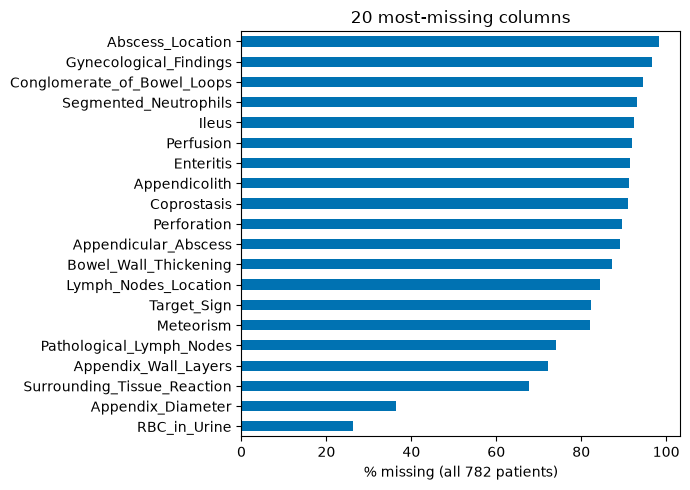

In [2]:
data.download()                 # downloads from Zenodo only if data/ is empty (523 MB, md5-checked)
full = data.load_all()
print("rows, columns:", full.shape)
display(full[["Age", "Sex", "BMI", "WBC_Count", "CRP", "Appendix_Diameter", "Diagnosis"]].head())
print(full.Diagnosis.value_counts(dropna=False))
miss = full.isna().mean().mul(100).sort_values(ascending=False)
miss.head(20).iloc[::-1].plot.barh(figsize=(7, 5), color="#0072B2")
plt.xlabel("% missing (all 782 patients)"); plt.title("20 most-missing columns"); plt.tight_layout(); plt.show()

## Cohort

Cohort = diagnosis + `US_Number` + at least one image: 578 patients, 66% appendicitis (enriched vs 59%). One row per patient, so a patient's images can never be split across train and test.

patients in spreadsheet            782
... with a diagnosis               780
... and a US_Number                759
cohort (... and >=1 image file)    578
dtype: int64 

images in cohort: 1721  | per patient: median 2, mean 2.98, max 15
cohort balance: 382 appendicitis / 196 no appendicitis (66% positive)


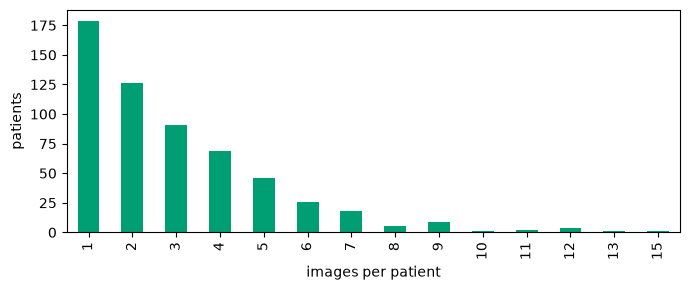

In [3]:
d, imgs = data.load_cohort()      # diagnosis + US_Number + at least one image
n_img = pd.Series({n: len(imgs[n]) for n in d.US_Number})
funnel = pd.Series({
    "patients in spreadsheet": len(full),
    "... with a diagnosis": full.Diagnosis.notna().sum(),
    "... and a US_Number": full.dropna(subset=["Diagnosis", "US_Number"]).shape[0],
    "cohort (... and >=1 image file)": len(d)})
print(funnel, "\n")
print(f"images in cohort: {n_img.sum()}  | per patient: median {n_img.median():.0f}, mean {n_img.mean():.2f}, max {n_img.max()}")
print(f"cohort balance: {d.y.sum()} appendicitis / {(1 - d.y).sum()} no appendicitis ({100 * d.y.mean():.0f}% positive)")
n_img.value_counts().sort_index().plot.bar(figsize=(7, 3), color="#009E73")
plt.xlabel("images per patient"); plt.ylabel("patients"); plt.tight_layout(); plt.show()

## Example images

Images are full scanner screenshots (menus, timestamps, calipers, printed measurements) and are fed to the model uncropped, so image features may encode overlays rather than anatomy.

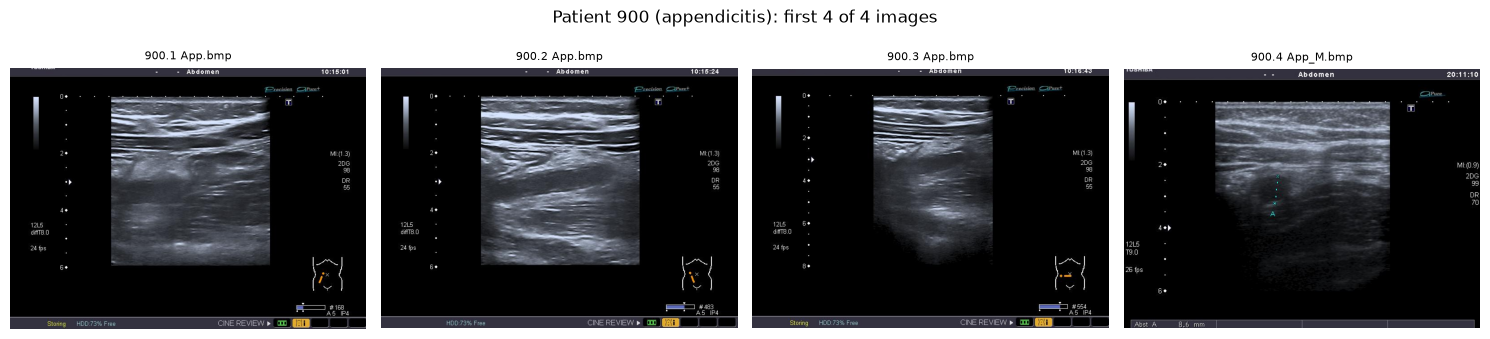

In [4]:
n = n_img[n_img >= 4].index[0]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, p in zip(axs, imgs[n][:4]):
    ax.imshow(Image.open(p)); ax.axis("off"); ax.set_title(p.name[:28], fontsize=8)
label = "appendicitis" if d.y[d.US_Number == n].iloc[0] else "no appendicitis"
fig.suptitle(f"Patient {n} ({label}): first 4 of {n_img[n]} images"); plt.tight_layout(); plt.show()

## Split

60/20/20, stratified, by patient, seed 0. Train fits models, validation picks settings and the temperature, test is used only for reporting. The overlap count must be 0.

In [5]:
s = data.split(d)                 # 60/20/20, stratified, PATIENT level, seed 0
y = d.y.values
print(pd.DataFrame({k: {"patients": len(v), "appendicitis": int(y[v].sum()),
                        "% positive": round(100 * y[v].mean(), 1)} for k, v in s.items()}).T)
ids = {k: set(d.US_Number.iloc[v]) for k, v in s.items()}
print("patients in more than one split:",
      len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"]))

       patients  appendicitis  % positive
train     346.0         228.0        65.9
val       116.0          77.0        66.4
test      116.0          77.0        66.4
patients in more than one split: 0


## Image embeddings

Frozen ImageNet ResNet-50: 2048 numbers per image, averaged per patient. First run takes ~2 min, then it is cached in `data/`.

In [6]:
E = data.embed(d, imgs)           # first run ~2 min on CPU, then cached in data/
print("embedding matrix (patients x features):", E.shape)

embedding matrix (patients x features): (578, 2048)


## Models

Tabular LR, Tabular GB, Image LR, Fused LR (table + 32 image PCs) and a concept bottleneck. Settings are chosen on validation AUROC; a value at the edge of the grid (1e-4 or 100) means the grid limit was hit.

In [7]:
out, ex = models.fit_all(d, E, s, y)           # a few seconds
yv, yt = y[s["val"]], y[s["test"]]
raw = {m: p[1] for m, p in out.items()}        # test probabilities of each model
print("chosen settings:", {"tab_lr C": ex["tab_lr"].C, "img_lr C": ex["img_lr"].C, "fused_lr C": ex["fused_lr"].C,
      "gb": (ex["tab_gb"].n_estimators, ex["tab_gb"].max_depth), "cbm label C": ex["cbm"]["label_head"].C})

chosen settings: {'tab_lr C': 1.0, 'img_lr C': 0.0001, 'fused_lr C': 0.1, 'gb': (200, 2), 'cbm label C': 100.0}


## Temperature scaling

One number T per model, fit on validation: T < 1 sharpens probabilities, T > 1 softens them. AUROC is unchanged.

In [8]:
Tm = {m: models.fit_temperature(yv, p[0]) for m, p in out.items()}
temp = {m: models.apply_temperature(raw[m], Tm[m]) for m in out}
print({ev.LABELS[m]: round(float(t), 2) for m, t in Tm.items()})

{'Tabular LR': 1.0, 'Tabular GB': 0.94, 'Image LR': 0.77, 'Fused LR': 0.61, 'Concept bottleneck': 0.88}


## Discrimination

Bootstrap: 1000 resamples of the 116 test patients. Values are `estimate [95% CI]`.

,AUROC,AUPRC,Sens@90Spec
Tabular LR,"0.963 [0.929, 0.988]","0.982 [0.963, 0.995]","0.883 [0.775, 0.975]"
Tabular GB,"0.969 [0.938, 0.991]","0.984 [0.965, 0.996]","0.909 [0.702, 0.987]"
Image LR,"0.635 [0.520, 0.743]","0.721 [0.622, 0.849]","0.052 [0.000, 0.373]"
Fused LR,"0.952 [0.909, 0.982]","0.979 [0.960, 0.993]","0.883 [0.795, 0.958]"
Concept bottleneck,"0.854 [0.771, 0.923]","0.907 [0.844, 0.959]","0.416 [0.200, 0.803]"


AUROC Fused LR minus Tabular LR: -0.012 [-0.039, +0.009]
AUROC Fused LR minus Concept bottleneck: +0.098 [+0.032, +0.173]


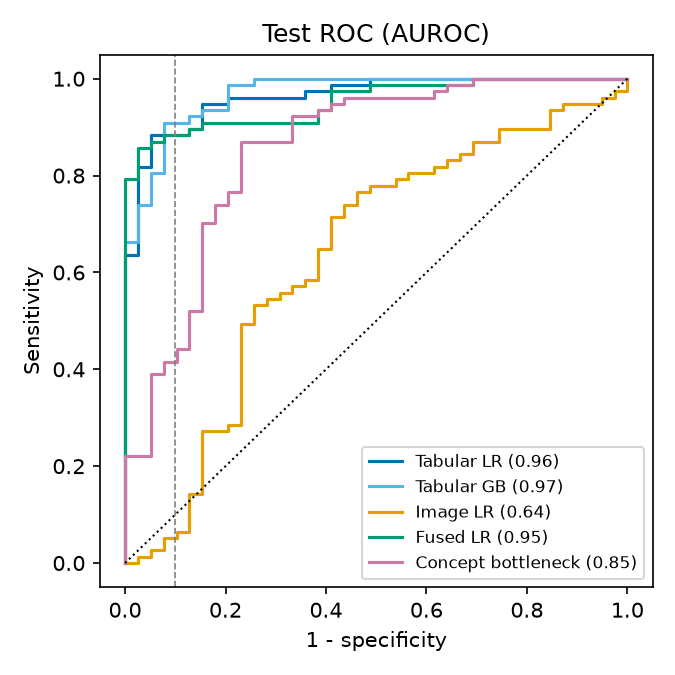

In [9]:
# Resample the 116 test patients 1000 times (about 1 minute). Same resamples for every model -> paired differences.
boot = ev.bootstrap(yt, {**raw, **{m + "+temp": temp[m] for m in out}})

def tbl(metrics, suffix=""):
    f = lambda m, k: "{:.3f} [{:.3f}, {:.3f}]".format(boot[(m + suffix, k)][0], *ev.ci(boot[(m + suffix, k)][1]))
    return pd.DataFrame({ev.LABELS[m]: {k: f(m, k) for k in metrics} for m in out}).T

display(tbl(["AUROC", "AUPRC", "Sens@90Spec"]))
for a, b in [("fused_lr", "tab_lr"), ("fused_lr", "cbm")]:
    est = boot[(a, "AUROC")][0] - boot[(b, "AUROC")][0]
    lo, hi = ev.ci(boot[(a, "AUROC")][1] - boot[(b, "AUROC")][1])
    print(f"AUROC {ev.LABELS[a]} minus {ev.LABELS[b]}: {est:+.3f} [{lo:+.3f}, {hi:+.3f}]")
ev.plot_roc(yt, raw, FIG / "roc.png"); show("roc.png")

- **Tabular ~0.96-0.97** (gradient boosting and logistic regression are indistinguishable: the CIs overlap almost entirely). The table includes the radiologist's own ultrasound findings and clinical scores, so this is not a screening result.
- **Image-only ~0.64** [0.52, 0.74]: barely above chance (0.5), and inside the shuffled-label range in the last section.
- **Fused minus tabular = -0.012 [-0.039, +0.009]**: no detectable gain from images. A small difference either way cannot be ruled out, and with tabular already at ~0.96 there is little room to improve.
- **Fused minus bottleneck = +0.098 [+0.032, +0.173]**: the bottleneck is worse, but it also sees fewer inputs and is not clearly above chance in the shuffled-label test, so this is not the pure cost of interpretability.

## Confusion matrices

The two best models on the test set (77 appendicitis, 39 not), threshold 0.5 (not tuned). Rows are the true class, columns the prediction: bottom-left = false negatives (missed appendicitis), top-right = false positives.

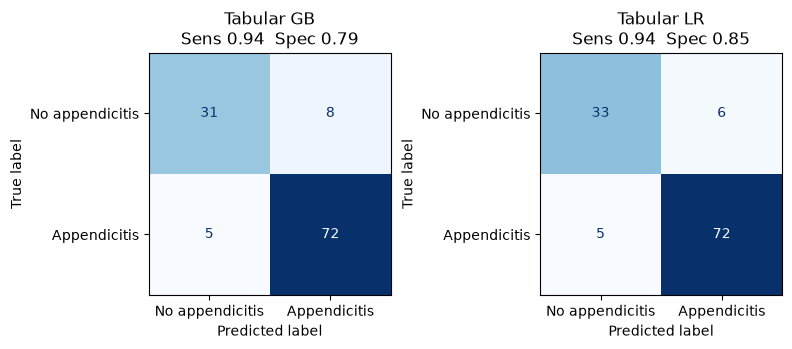

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, m in zip(axs, ["tab_gb", "tab_lr"]):          # the two best models
    pred = raw[m] >= 0.5
    tn, fp, fn, tp = confusion_matrix(yt, pred).ravel()
    ConfusionMatrixDisplay.from_predictions(yt, pred, display_labels=["No appendicitis", "Appendicitis"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{ev.LABELS[m]}\nSens {tp / (tp + fn):.2f}  Spec {tn / (tn + fp):.2f}")
plt.tight_layout(); plt.show()

Both models miss the same 5 of 77 appendicitis cases (false negatives, the costlier error clinically). Gradient boosting has 8 false positives and logistic regression 6; that difference of 2 patients was not tested and is well within noise at n = 116.

## Calibration

RAW probabilities:


,ECE,Brier
Tabular LR,"0.057 [0.049, 0.125]","0.073 [0.041, 0.106]"
Tabular GB,"0.073 [0.044, 0.124]","0.069 [0.037, 0.107]"
Image LR,"0.028 [0.019, 0.129]","0.218 [0.189, 0.246]"
Fused LR,"0.084 [0.065, 0.151]","0.088 [0.060, 0.119]"
Concept bottleneck,"0.009 [0.005, 0.103]","0.215 [0.189, 0.241]"


After temperature scaling:


,ECE,Brier
Tabular LR,"0.059 [0.050, 0.126]","0.073 [0.041, 0.106]"
Tabular GB,"0.076 [0.043, 0.127]","0.071 [0.037, 0.109]"
Image LR,"0.106 [0.049, 0.194]","0.219 [0.183, 0.253]"
Fused LR,"0.088 [0.065, 0.156]","0.092 [0.058, 0.131]"
Concept bottleneck,"0.090 [0.033, 0.173]","0.215 [0.185, 0.244]"


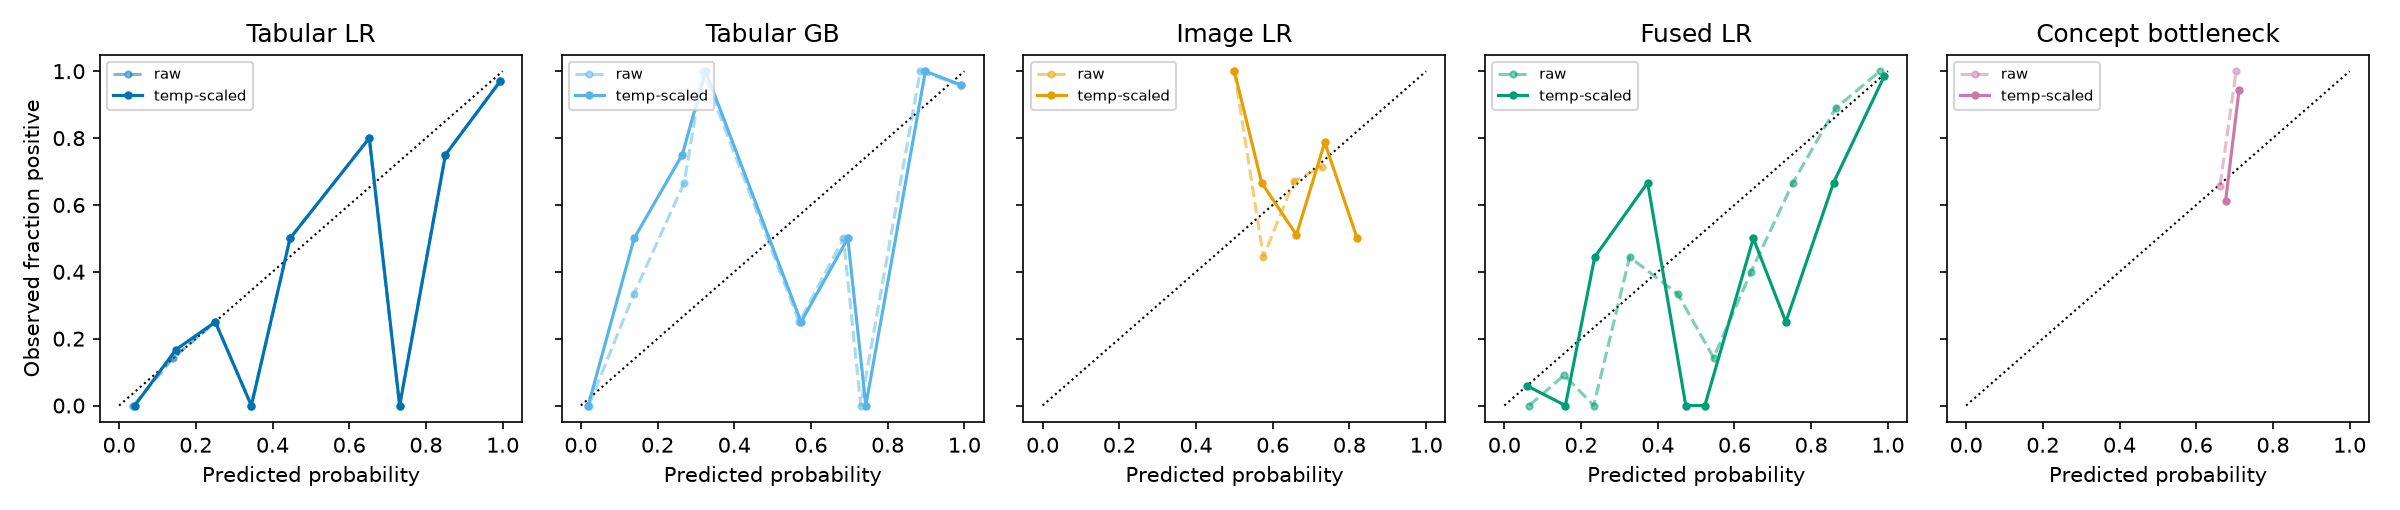

In [11]:
print("RAW probabilities:");           display(tbl(["ECE", "Brier"]))
print("After temperature scaling:");   display(tbl(["ECE", "Brier"], "+temp"))
ev.plot_reliability(yt, raw, temp, FIG / "rel.png"); show("rel.png")

- Temperature scaling did **not** help on the test set. Tabular: ECE and Brier essentially unchanged. Fused: slightly worse. Image-only and bottleneck: ECE gets worse (0.03 to 0.11 and 0.01 to 0.09). With only 116 validation patients, T is noisy.
- The low raw ECE of image-only and bottleneck is misleading: their predictions sit near the base rate (bottleneck 0.63-0.71), so they look calibrated while saying almost nothing. Brier shows it: 0.218 and 0.215 vs 0.223 for always predicting the base rate.

## Explainability (SHAP)

Each dot is a test patient; right = pushes toward appendicitis, colour = feature value.

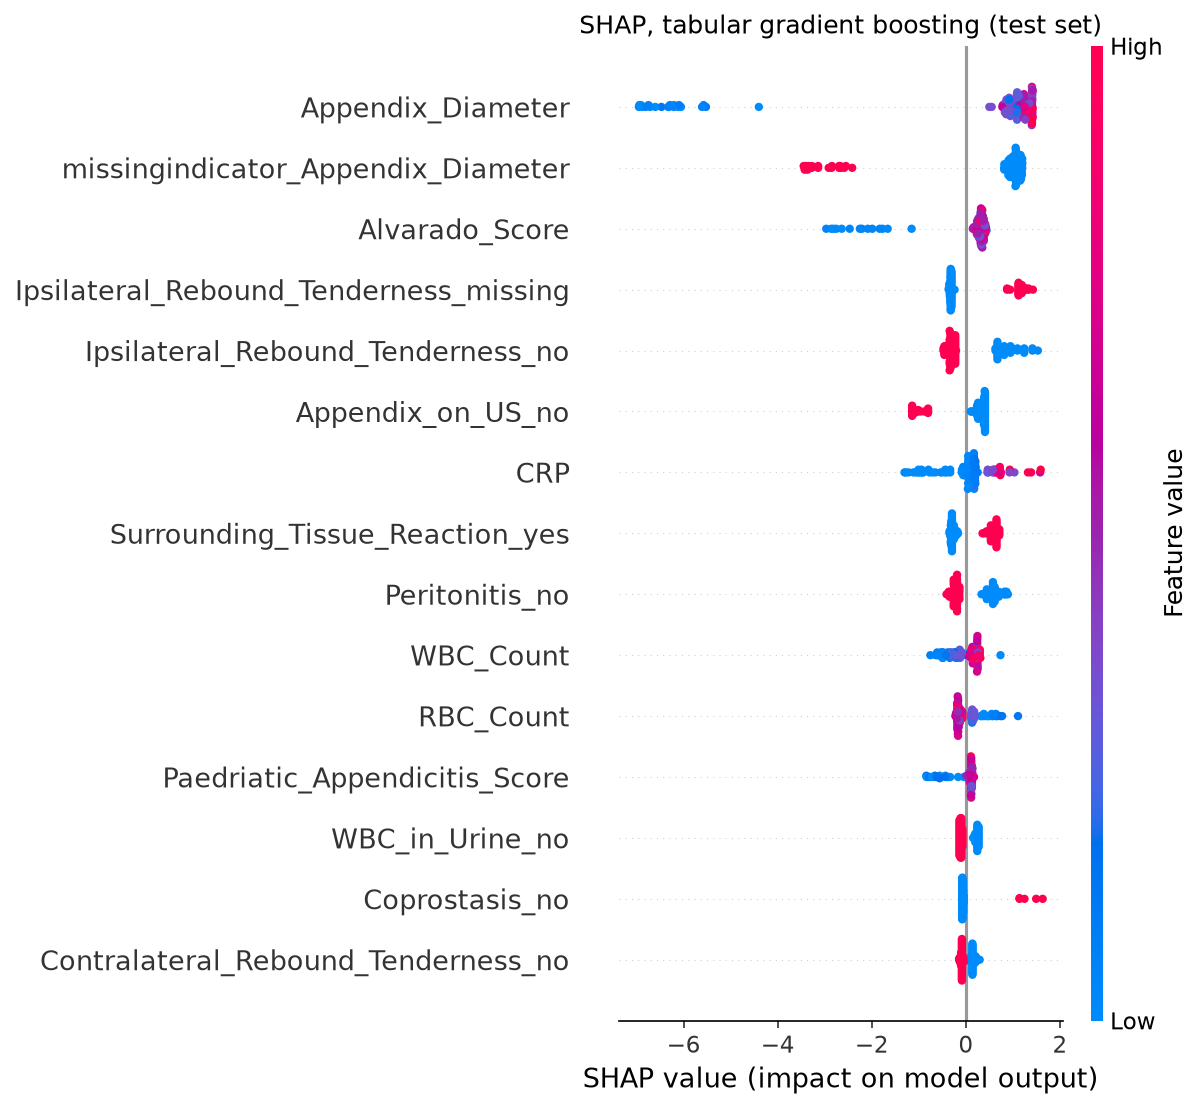

In [12]:
ev.plot_shap(ex["tab_gb"], ex["pre"], ex["T"]["test"], FIG / "shap.png"); show("shap.png")

Top features: appendix diameter (a small diameter pushes strongly away from appendicitis), whether the diameter is *missing* (missing also pushes away), and the Alvarado score. The model relies heavily on missing-indicator features; whether missingness adds information beyond the observed values was not tested (no ablation). SHAP explains the model, not causes, and correlated features share credit.

## Concept bottleneck

Predicts 11 clinical concepts from image + demographics + labs, then the diagnosis from those concepts only.

,n test patients,concept AUROC,label-head coef
concept,,,
Appendix_on_US,116,0.61,-2.98
Free_Fluids,112,0.61,0.71
Lower_Right_Abd_Pain,115,0.39,1.02
Migratory_Pain,115,0.50,4.97
Contralateral_Rebound_Tenderness,115,0.51,2.05
Psoas_Sign,110,0.61,-4.59
Coughing_Pain,114,0.50,-2.79
Nausea,116,0.73,10.26
Loss_of_Appetite,116,0.64,2.68


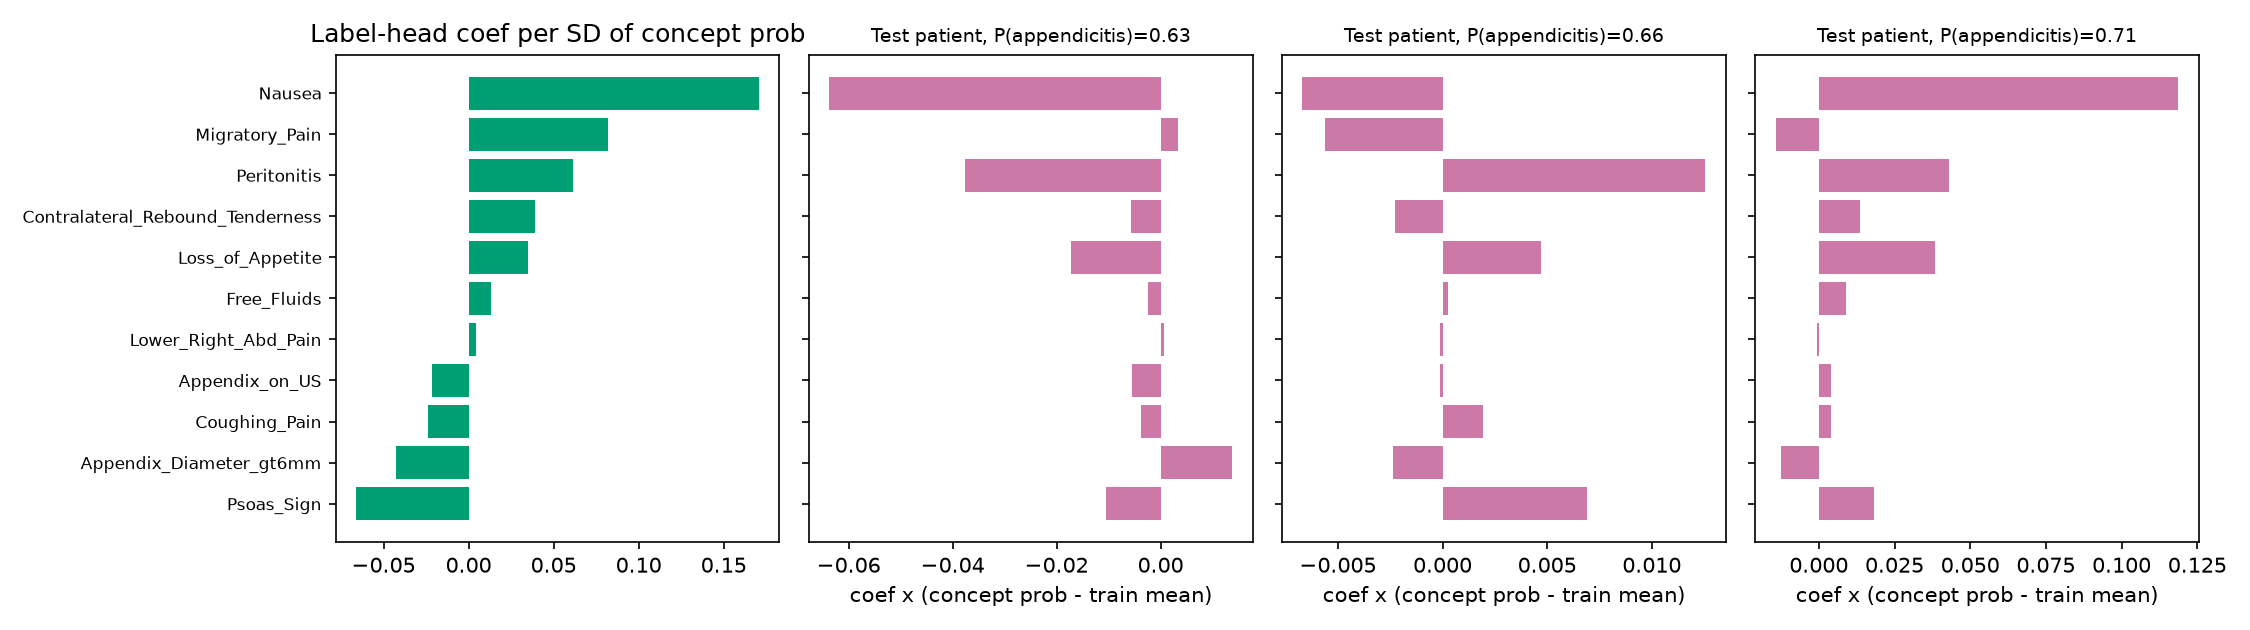

In [13]:
cbm = ex["cbm"]
Cm = data.concepts(d).to_numpy()[s["test"]]
ok = lambda j: ~np.isnan(Cm[:, j])
display(pd.DataFrame({
    "concept": cbm["names"],
    "n test patients": [int(ok(j).sum()) for j in range(Cm.shape[1])],
    "concept AUROC": [round(roc_auc_score(Cm[ok(j), j], cbm["heads"][j].predict_proba(cbm["H"]["test"][ok(j)])[:, 1]), 2)
                      for j in range(Cm.shape[1])],
    "label-head coef": cbm["label_head"].coef_[0].round(2)}).set_index("concept"))
ev.plot_concepts(cbm, raw["cbm"], FIG / "cbm.png"); show("cbm.png")

Most concepts are poorly predicted (AUROC 0.4-0.8) and some coefficients are not clinically coherent (e.g. negative for psoas sign), so the plot only illustrates the mechanism. The gap to the fused model is confounded with the bottleneck's smaller inputs, and its own AUROC is unstable (see the shuffled-label test), so treat it as weak evidence.

## Sanity check: shuffled labels

Shuffle train+val labels, keep test labels real, refit everything, 20 times. A sound pipeline should average ~0.5.

In [14]:
# (a) Label-permutation test: shuffle train+val labels, keep test labels real, refit everything.
N_PERM = 20                                    # about 1 minute; use 5 for a quick look
tv = np.concatenate([s["train"], s["val"]])
null = {m: [] for m in out}
for seed in range(N_PERM):
    ys = y.copy(); ys[tv] = np.random.default_rng(seed).permutation(y[tv])
    for m, p in models.fit_all(d, E, s, ys)[0].items():
        null[m].append(roc_auc_score(yt, p[1]))
print(pd.DataFrame({ev.LABELS[m]: {"real AUROC": roc_auc_score(yt, raw[m]), "shuffled mean": np.mean(v),
                                   "shuffled SD": np.std(v), "shuffled min": min(v), "shuffled max": max(v)}
                    for m, v in null.items()}).T.round(3))

                    real AUROC  shuffled mean  shuffled SD  shuffled min  shuffled max
Tabular LR               0.963          0.522        0.147         0.191         0.819
Tabular GB               0.969          0.501        0.076         0.393         0.633
Image LR                 0.635          0.508        0.089         0.333         0.637
Fused LR                 0.952          0.517        0.116         0.316         0.782
Concept bottleneck       0.854          0.391        0.271         0.135         0.870


Means are near 0.5 for four models, and the tabular and fused real AUROCs exceed every shuffled value, so their signal is not an artifact of the pipeline. A single shuffled run can land far from 0.5, hence 20 runs. The bottleneck (bimodal, real 0.854 below its shuffled max 0.870) and image-only (0.635 within its range) are not clearly above chance. This test does not address the other caveats above (clinician findings in the table, missingness).

**Limits:** 116 test patients, one split, one centre, frozen ImageNet features. See [README.md](README.md).